# 03 — Geração das respostas

Este notebook registra a etapa de **geração**: do pedido montado para cada pergunta até a resposta final, com os guardrails de saída e o fallback para uma segunda LLM. O **mérito** das respostas (se estão corretas e apoiadas nas fontes) é avaliado pelo juiz no notebook 04.

Fluxo de cada pergunta:

```
pergunta
  → guardrail de entrada (classifica a ação, mascara dados pessoais, remove instruções suspeitas)
  → ação sem busca (institucional, consulta individual, fora do escopo, outra jurisdição) → resposta fixa
  → ação com busca (responder, orientar_sem_aconselhar):
       recuperação conjunta (3 artigos + 3 decisões) → prompt jurídico
       → LLM A (Qwen3 8B) ── falhou? ──→ LLM B (Llama 3.1 8B) ── falhou? ──→ resposta segura
  → guardrail de saída (citações, dispositivos, promessa, consulta individual, aviso legal)
  → resposta final
```

**Dados.** As 137 perguntas da base de avaliação: 100 da curadoria (avaliação 09), 20 dos conjuntos dev/test aprovados da legislação e 17 de suporte da jurisprudência. As métricas vêm de `reports/integracao/geracao/`; pedidos e respostas completos ficam fora do Git (`output/kaggle/geracao/`), porque contêm perguntas protegidas e trechos de decisões.

## 1. Configuração

In [1]:
from pathlib import Path
import sys, json
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / 'src/integracao').exists())
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
from src.integracao import geracao as ger
from src.integracao import guardrails as g

pd.set_option('display.width', 200); pd.set_option('display.max_colwidth', 90)
RELATORIOS = ROOT / 'reports/integracao/geracao'
revisao = pd.read_csv(RELATORIOS / 'revisao_saida.csv')
resumo = json.loads((RELATORIOS / 'resumo_kernel.json').read_text(encoding='utf-8'))

# Estilo dos gráficos: uma série por gráfico, cor única, eixos discretos.
COR = '#2a78d6'
TEXTO, TEXTO_2 = '#0b0b0b', '#52514e'
plt.rcParams.update({'axes.spines.top': False, 'axes.spines.right': False, 'axes.edgecolor': '#c3c2b7',
                     'axes.labelcolor': TEXTO_2, 'xtick.color': TEXTO_2, 'ytick.color': TEXTO_2,
                     'axes.titlecolor': TEXTO, 'axes.titlesize': 11, 'font.size': 9, 'figure.dpi': 110})

display(pd.DataFrame([
    dict(item='LLM A (geração)', valor=ger.MODELO_GERACAO),
    dict(item='LLM B (fallback)', valor=ger.MODELO_FALLBACK),
    dict(item='opções de geração', valor=json.dumps(ger.OPCOES_GERACAO)),
    dict(item='modo de raciocínio', valor='desligado (think=False)'),
    dict(item='Ollama', valor=resumo.get('ollama', {}).get('version')),
    dict(item='GPU', valor=resumo.get('gpu', '').replace('\n', ' + ')),
]).set_index('item'))

,valor
item,
LLM A (geração),qwen3:8b-q8_0
LLM B (fallback),llama3.1:8b
opções de geração,"{""temperature"": 0, ""seed"": 42, ""num_predict"": 1200, ""num_ctx"": 16384}"
modo de raciocínio,desligado (think=False)
Ollama,0.40.16
GPU,"Tesla T4, 15360 MiB + Tesla T4, 15360 MiB"


**Por que essa configuração.**

- **Qwen3 8B, quantização Q8, no Kaggle (GPU T4).** No teste com 3 perguntas reais, o `qwen3:4b-instruct` repetiu os dois erros apontados pela revisora (parágrafo errado do art. 73 e resposta sobre o processo da pessoa sem ressalva); o 8B não repetiu. A Q8 perde muito pouco em relação ao modelo completo e cabe na T4 (15 GB). O Kaggle é gratuito e não depende da máquina local.
- **Temperatura 0 e semente fixa**, para que a geração seja reprodutível.
- **Contexto de 16.384 tokens.** O prompt com 6 fontes chega a cerca de 10 mil tokens; com o padrão de 8.192, o Ollama cortaria o início do prompt sem avisar.
- **Prompt de sistema:** `SYSTEM_PROMPT_LEGAL` do grupo, sem alteração (`src/integracao/prompt_juridico.py`). Nas perguntas `orientar_sem_aconselhar`, uma nota final pede a regra geral e o encaminhamento, sem dizer o que a pessoa deve fazer.
- **Cada pedido tem um hash** (modelo + opções + mensagens). Na importação, cada resposta é conferida contra o hash do pedido que a gerou.

## 2. Perguntas e ações

O guardrail de entrada decide a ação de cada pergunta. Só `responder` e `orientar_sem_aconselhar` vão para a busca e para a LLM; as demais recebem uma resposta fixa, escrita para cada situação.

por origem (com LLM): {'curadoria_09': 80, 'jurisprudencia_suporte': 16, 'legislacao_dev': 8, 'legislacao_test': 7}


,perguntas,caminho
acao,,
responder,99,LLM
orientar_sem_aconselhar,12,LLM
consulta_individual,12,resposta fixa
institucional,11,resposta fixa
fora_escopo,2,resposta fixa
outra_jurisdicao,1,resposta fixa


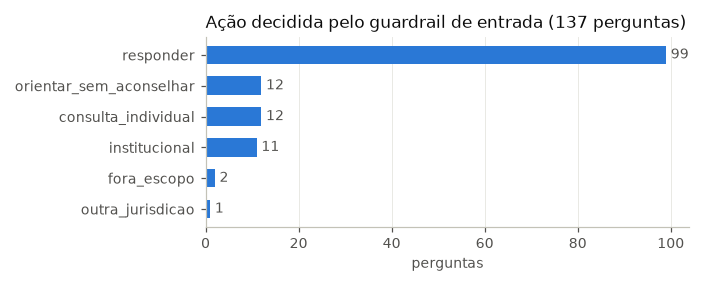

In [2]:
ORDEM = ['responder', 'orientar_sem_aconselhar', 'consulta_individual', 'institucional', 'fora_escopo', 'outra_jurisdicao']
acoes = revisao.groupby('acao').agg(perguntas=('pergunta_id', 'size'), com_llm=('precisa_llm', 'sum')).reindex(ORDEM)
acoes['caminho'] = ['LLM' if c else 'resposta fixa' for c in acoes['com_llm']]
display(acoes[['perguntas', 'caminho']])
print('por origem (com LLM):', revisao[revisao.precisa_llm].groupby('origem').size().to_dict())

fig, ax = plt.subplots(figsize=(6.4, 2.6))
y = range(len(acoes))[::-1]
ax.barh(list(y), acoes['perguntas'], color=COR, height=0.6)
ax.set_yticks(list(y), acoes.index)
for yi, valor in zip(y, acoes['perguntas']):
    ax.text(valor + 1, yi, str(int(valor)), va='center', color=TEXTO_2)
ax.set_xlabel('perguntas')
ax.set_title('Ação decidida pelo guardrail de entrada (137 perguntas)', loc='left')
ax.grid(axis='x', color='#e8e7e2', linewidth=0.6)
ax.set_axisbelow(True)
plt.tight_layout()
plt.show()

## 3. Integridade da geração

Cada resposta da LLM é validada antes de qualquer revisão de conteúdo: hash igual ao do pedido, texto com pelo menos 80 caracteres, sem corte no limite de tokens (`done_reason = length`) e sem raciocínio interno exposto (`<think>`). O kernel refaz automaticamente uma resposta cortada, com o dobro do limite.

,pedidos_llm,respostas,validas,com_problema
0,111,111,111,0


,segundos_geracao,segundos_recuperacao,tokens_saida
média,36.8,15.4,544.2
mediana,34.4,15.1,515.0
mínimo,16.6,9.4,232.0
máximo,126.8,19.8,987.0


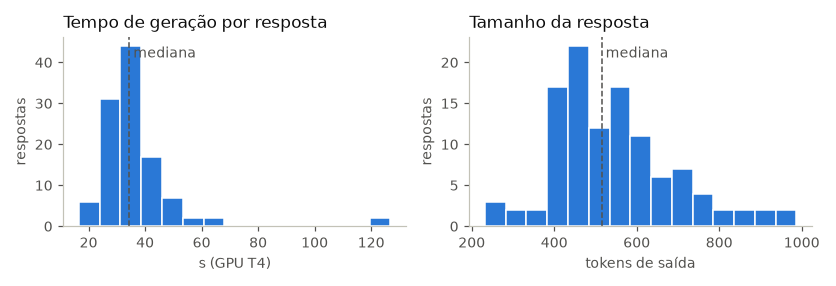

In [3]:
llm = revisao[revisao.precisa_llm]
display(pd.DataFrame([dict(pedidos_llm=resumo['pedidos_llm'], respostas=resumo['respostas'], validas=resumo['validas'],
                           com_problema=int((~llm.valida).sum()))]))
tempos = llm[['segundos_geracao', 'segundos_recuperacao', 'tokens_saida']].describe().loc[['mean', '50%', 'min', 'max']]
tempos.index = ['média', 'mediana', 'mínimo', 'máximo']
display(tempos.round(1))

fig, axes = plt.subplots(1, 2, figsize=(7.6, 2.6))
for ax, coluna, titulo, unidade in ((axes[0], 'segundos_geracao', 'Tempo de geração por resposta', 's (GPU T4)'),
                                    (axes[1], 'tokens_saida', 'Tamanho da resposta', 'tokens de saída')):
    ax.hist(llm[coluna], bins=15, color=COR, edgecolor='white', linewidth=1)
    ax.axvline(llm[coluna].median(), color=TEXTO_2, linewidth=1, linestyle='--')
    ax.text(llm[coluna].median(), ax.get_ylim()[1] * 0.95, ' mediana', color=TEXTO_2, va='top')
    ax.set_title(titulo, loc='left')
    ax.set_xlabel(unidade)
    ax.set_ylabel('respostas')
plt.tight_layout()
plt.show()

O tempo de recuperação (cerca de 15 s por pergunta) é medido na máquina local, na CPU, ao montar os pedidos; o de geração, na GPU T4 do Kaggle. Somados, ficam perto de 50 s por pergunta, o que serve para avaliação em lote, mas é lento para uso interativo.

## 4. Guardrails de saída

Cada resposta passa pelas regras do notebook 02. Regras **bloqueantes** reprovam a resposta; as **informativas** só registram um alerta. O aviso legal ausente é acrescentado automaticamente à resposta final.

bloqueantes nas respostas da LLM: nenhum


,perguntas,aprovadas
precisa_llm,,
resposta fixa,26,26
com LLM,111,111


,respostas com o alerta,bloqueante
alertas,,
aviso_legal_ausente,109,False
afirmacao_sem_fonte,79,False
artigo_sem_fonte,10,False


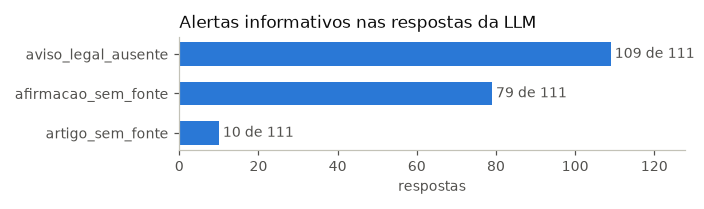

In [4]:
aprov = revisao.groupby('precisa_llm').agg(perguntas=('aprovada', 'size'), aprovadas=('aprovada', 'sum'))
aprov.index = aprov.index.map({True: 'com LLM', False: 'resposta fixa'})
display(aprov)

def contar(coluna, base):
    return base[coluna].astype('string').fillna('').str.split(', ').explode().loc[lambda s: s != ''].value_counts()

alertas = contar('alertas', llm).rename('respostas com o alerta').to_frame()
alertas['bloqueante'] = alertas.index.isin(g.BLOQUEANTES)
display(alertas)
print('bloqueantes nas respostas da LLM:', contar('bloqueantes', llm).to_dict() or 'nenhum')

fig, ax = plt.subplots(figsize=(6.4, 1.9))
y = range(len(alertas))[::-1]
ax.barh(list(y), alertas.iloc[:, 0], color=COR, height=0.6)
ax.set_yticks(list(y), alertas.index)
for yi, valor in zip(y, alertas.iloc[:, 0]):
    ax.text(valor + 1, yi, f'{int(valor)} de {len(llm)}', va='center', color=TEXTO_2)
ax.set_xlim(0, len(llm) * 1.15)
ax.set_title('Alertas informativos nas respostas da LLM', loc='left')
ax.set_xlabel('respostas')
plt.tight_layout()
plt.show()

**Leitura.**

- Nenhuma resposta da LLM foi reprovada por regra bloqueante: não há citação de fonte inexistente, número atribuído ao dispositivo errado, promessa de resultado nem resposta além do escopo.
- **Isso não prova que as respostas estão corretas.** As regras conferem forma e coerência com as fontes entregues, não a interpretação jurídica. A revisão de mérito é o papel do juiz (notebook 04).
- `afirmacao_sem_fonte` em 79 das 111 respostas: em boa parte delas, mais de 60% das frases jurídicas não trazem `[Fonte N]`. O conteúdo pode estar certo, mas o leitor não consegue conferir de onde veio. É o principal ponto de melhoria do prompt.
- `aviso_legal_ausente` em quase todas: o modelo raramente escreve o aviso por conta própria; ele é acrescentado na saída.

**Correção feita nesta etapa.** Na primeira importação, a regra `sem_fontes` reprovava 14 respostas fixas (institucional, fora do escopo, outra jurisdição) só porque elas mencionam "Direito do Trabalho". A regra passou a valer apenas para ações que deveriam ter ido à busca; nas recusas, o excesso de conteúdo jurídico continua coberto por `resposta_alem_do_escopo`. A concordância com a revisora no notebook 02 continuou 9 de 9, e o caso virou teste automático.

## 5. Fallback para a LLM B

Quando a LLM A falha, o mesmo prompt vai para uma segunda LLM, de outra família. Se a segunda também falhar, a resposta é uma **resposta segura** que não afirma nada e encaminha a pessoa.

| Gatilho | Exemplos |
|---|---|
| falha técnica | erro ou tempo esgotado, resposta vazia ou curta, cortada no limite de tokens, raciocínio interno exposto |
| guardrail bloqueante | citação inexistente, dispositivo inconsistente, promessa de resultado, consulta individual sem ressalva ou pedindo dados |

**LLM B: Llama 3.1 8B (Meta).** Gratuita, roda no Ollama e cabe tanto na T4 quanto na GPU local de 8 GB. Precisa ser de outra família que o Qwen, para não errar do mesmo jeito, e diferente do juiz (Gemma), para que o juiz não avalie o próprio estilo.

A mesma regra serve ao uso em tempo real (`geracao.gerar_com_fallback`) e à avaliação em lote (`geracao.escolher_resposta`, aplicada na importação). Abaixo, a função com uma LLM simulada nos quatro cenários.

In [5]:
artigo_73 = ('Art. 73. Salvo nos casos de revezamento semanal ou quinzenal, o trabalho noturno terá remuneração superior '
             'a do diurno e, para esse efeito, sua remuneração terá um acréscimo de 20 % (vinte por cento), pelo menos, '
             'sobre a hora diurna.')
boa = ('O trabalho noturno tem acréscimo de pelo menos 20% sobre a hora diurna (art. 73 da CLT) [Fonte 1]. '
       'Esta resposta é informativa e não substitui a orientação de um advogado.')
citacao_errada = boa.replace('[Fonte 1]', '[Fonte 7]')
mensagens = [dict(role='system', content='...'), dict(role='user', content='Qual o adicional noturno?')]
pedido = dict(acao='responder', sinais=[], motivo='', pergunta_sanitizada='Qual o adicional noturno?',
              fontes=[dict(fonte='legislacao', conteudo=artigo_73, artigo_ref='Art. 73')], mensagens=mensagens,
              modelo=ger.MODELO_GERACAO, opcoes=ger.OPCOES_GERACAO,
              pedido_sha256=ger._hash(ger.MODELO_GERACAO, ger.OPCOES_GERACAO, mensagens))

def llm_simulada(respostas):
    def chamar(p):
        valor = respostas[p['modelo']]
        if isinstance(valor, Exception):
            raise valor
        return dict(resposta=valor, done_reason='stop', pedido_sha256=p['pedido_sha256'])
    return chamar

cenarios = {'A responde bem': {ger.MODELO_GERACAO: boa},
            'A dá erro técnico': {ger.MODELO_GERACAO: TimeoutError('tempo esgotado'), ger.MODELO_FALLBACK: boa},
            'A é bloqueada pelo guardrail': {ger.MODELO_GERACAO: citacao_errada, ger.MODELO_FALLBACK: boa},
            'A e B falham': {ger.MODELO_GERACAO: citacao_errada, ger.MODELO_FALLBACK: ''}}
linhas = []
for nome, respostas in cenarios.items():
    r = ger.gerar_com_fallback(pedido, llm_simulada(respostas))
    linhas.append(dict(cenario=nome, modelo_final=r['modelo'] or '(resposta segura)', motivo_a=r['motivo_a'], motivo_b=r['motivo_b']))
display(pd.DataFrame(linhas).set_index('cenario'))

,modelo_final,motivo_a,motivo_b
cenario,,,
A responde bem,qwen3:8b-q8_0,NaN,NaN
A dá erro técnico,llama3.1:8b,tecnico: sem resposta,NaN
A é bloqueada pelo guardrail,llama3.1:8b,guardrail: citacao_inexistente,NaN
A e B falham,(resposta segura),guardrail: citacao_inexistente,tecnico: sem resposta


In [6]:
print('respostas finais por modelo:', revisao['modelo_final'].fillna('resposta fixa').value_counts().to_dict())
print('pedidos que acionariam a LLM B:', int(revisao['motivo_fallback'].notna().sum()))
print('respostas seguras:', int(revisao['resposta_segura'].sum()))

respostas finais por modelo: {'qwen3:8b-q8_0': 111, 'resposta fixa': 26}
pedidos que acionariam a LLM B: 0
respostas seguras: 0


Nesta rodada, a LLM A não falhou em nenhuma das 111 perguntas, então o fallback não foi acionado. Para saber se a LLM B daria conta quando for necessária, ela gerou respostas para as mesmas 111 perguntas, só para comparação (seção 6); as respostas finais continuam sendo as do Qwen.

## 6. Qwen3 8B × Llama 3.1 8B

O Llama 3.1 8B gerou respostas para as mesmas 111 perguntas, com os mesmos prompts e as mesmas opções, no mesmo ambiente (Ollama 0.40.16, GPU T4). As respostas finais continuam sendo as do Qwen; esta comparação só verifica se a LLM B daria conta quando o fallback for acionado. Aqui entram validade, guardrails, citações e tempo; o mérito, com o juiz, fica no notebook 04.

In [7]:
comparacao = pd.read_csv(RELATORIOS / 'comparacao_llm_b.csv')
resumo_b = json.loads((RELATORIOS / 'resumo_kernel_llm_b.json').read_text(encoding='utf-8'))

def tem(coluna, codigo):
    return comparacao[coluna].astype('string').fillna('').str.contains(codigo)

tabela = comparacao.assign(sem_fonte=tem('alertas', 'afirmacao_sem_fonte'), artigo_fora=tem('alertas', 'artigo_sem_fonte'),
                           sem_citacao=comparacao.citacoes == 0).groupby('modelo').agg(
    respostas=('valida', 'size'), validas=('valida', 'sum'), aprovadas_guardrail=('aprovada', 'sum'),
    citacoes_por_resposta=('citacoes', 'mean'), respostas_sem_citacao=('sem_citacao', 'sum'),
    alerta_afirmacao_sem_fonte=('sem_fonte', 'sum'), alerta_artigo_sem_fonte=('artigo_fora', 'sum'),
    segundos_media=('segundos', 'mean'), tokens_saida_media=('tokens_saida', 'mean'))
display(tabela.round(1).astype(object).T)

modelo,llama3.1:8b,qwen3:8b-q8_0
respostas,111,111
validas,111,111
aprovadas_guardrail,111,111
citacoes_por_resposta,2.3,3.6
respostas_sem_citacao,37,21
alerta_afirmacao_sem_fonte,85,79
alerta_artigo_sem_fonte,1,10
segundos_media,22.8,36.8
tokens_saida_media,440.9,544.2


**Leitura.**

- **As duas LLMs são confiáveis tecnicamente:** 111 de 111 respostas válidas cada uma, todas em português, nenhuma reprovada por regra bloqueante.
- **O Llama é mais rápido** (cerca de 23 s por resposta, contra 37 s do Qwen) e escreve respostas mais curtas.
- **O Llama cita menos as fontes:** em média 2,3 citações `[Fonte N]` por resposta, contra 3,6 do Qwen, e 37 respostas sem nenhuma citação, contra 21 do Qwen. Em compensação, quase não cita artigos fora das fontes entregues.
- **Na leitura de um exemplo público (q_test_03),** o conteúdo do Llama está correto (20% do art. 73 e o horário das 22h às 5h no § 2º), mas ele repete um parágrafo inteiro. Repetição não é verificada pelos guardrails.
- **Conclusão para o fallback:** o Llama serve como reserva técnica, mas tende a fundamentar menos. Se quem respondeu foi a LLM B, isso deve ficar registrado na resposta e na avaliação.
- A comparação favorece o Qwen, porque o prompt foi ajustado olhando respostas dessa família.

## 7. Exemplos

Respostas a perguntas públicas (conjuntos dev/test aprovados, já versionados). As respostas completas ficam fora do Git; esta célula só as mostra quando o arquivo local existe.

In [8]:
arquivo = ROOT / 'output/kaggle/geracao/respostas_revisadas.jsonl'
EXEMPLOS = ['q_test_03', 'q_test_neg_02']
if arquivo.exists():
    for l in arquivo.read_text(encoding='utf-8').splitlines():
        r = json.loads(l)
        if r['pergunta_id'] in EXEMPLOS:
            alertas = sorted({a['codigo'] for a in r['alertas']})
            display(Markdown(f"**{r['pergunta_id']}** · ação `{r['acao']}` · modelo `{r.get('modelo_final') or 'resposta fixa'}` "
                             f"· alertas: {', '.join(alertas) or 'nenhum'}\n\n**Pergunta:** {r['pergunta_sanitizada']}\n\n"
                             + '\n'.join('> ' + linha for linha in r['resposta_final'].splitlines())))
else:
    print('respostas completas não disponíveis nesta máquina (output/kaggle/geracao/ fica fora do Git)')

**q_test_03** · ação `responder` · modelo `qwen3:8b-q8_0` · alertas: aviso_legal_ausente

**Pergunta:** Como é calculada a remuneração do trabalho noturno urbano em comparação ao diurno?

> Resposta direta:  
> A remuneração do trabalho noturno urbano é calculada com um acréscimo mínimo de 20% sobre a hora diurna, conforme previsto na CLT e na Lei Complementar 150/2015. No entanto, convenções coletivas podem estabelecer percentuais superiores, como 40%, conforme jurisprudência.
> 
> Fundamentação:  
> De acordo com o **Art. 73 da CLT**, o trabalho noturno urbano deve ter remuneração superior à do diurno, com acréscimo de **pelo menos 20%** sobre a hora diurna [Fonte 1]. Além disso, o **Art. 14 da Lei Complementar 150/2015** também estabelece que o trabalho noturno deve ter **acréscimo de, no mínimo, 20%** sobre o valor da hora diurna [Fonte 2].  
> 
> A jurisprudência do **TST** e do **TRT-17** reconhece que convenções coletivas podem estabelecer percentuais superiores ao legal, como **40%**, desde que pactuados entre empregador e empregado [Fonte 4 e Fonte 5].  
> 
> Além disso, o **Art. 7º da Lei 5.889/1973** prevê um acréscimo de **25%** para o trabalho noturno em atividades rurais, mas esse não se aplica ao urbano [Fonte 3].  
> 
> Portanto, o cálculo do adicional noturno urbano segue o padrão legal de **20%**, mas pode ser maior se houver pactuação em convenção coletiva.
> 
> Esta resposta é informativa e não substitui a orientação de um advogado, da Defensoria Pública ou do sindicato da categoria.

**q_test_neg_02** · ação `consulta_individual` · modelo `resposta fixa` · alertas: aviso_legal_ausente

**Pergunta:** Qual foi o fundamento utilizado pelo juiz na sentença do meu processo, cujo número e documentos não forneci?

> Não tenho acesso a processos, contas ou registros pessoais, então não consigo informar a situação do seu caso. Consulte o processo pelo número no site do tribunal (sistema PJe), ou fale com o advogado que acompanha a ação. Para o FGTS, o extrato fica no aplicativo FGTS da Caixa. Não envie aqui seu CPF, número do processo ou documentos.
> 
> Esta resposta é informativa e não substitui a orientação de um advogado, da Defensoria Pública ou do sindicato da categoria.

- **q_test_03** é a pergunta em que o sistema anterior errou o parágrafo do art. 73 (caso reprovado pela revisora).
- **q_test_neg_02** pergunta sobre a sentença do próprio processo. Agora ela recebe a resposta fixa de consulta individual: o sistema diz que não tem acesso, indica onde consultar e não pede dados.

## 8. Conclusões

- **A geração no Kaggle foi íntegra:** 111 de 111 respostas válidas, nenhuma cortada ou vazia, todas conferidas pelo hash do pedido. Média de 36,8 s por resposta na GPU T4, mais cerca de 15 s de recuperação.
- **Os guardrails não reprovaram nenhuma resposta da LLM,** mas isso mede forma, não mérito. O juiz (notebook 04) é que dirá se as respostas estão corretas.
- **Citação das fontes é o ponto fraco:** 79 das 111 respostas deixam a maior parte das frases jurídicas sem `[Fonte N]`. Ajustar o prompt para exigir a citação é o primeiro passo de melhoria.
- **O fallback está implementado e testado** (7 testes com LLM simulada), mas não foi acionado nesta rodada. Na comparação, o Llama 3.1 8B também gerou 111 respostas válidas, mais rápido, porém citando menos as fontes: serve como reserva técnica.

**Limites.**

- O prompt foi ajustado olhando respostas de modelos da família Qwen; isso favorece o Qwen na comparação com o Llama.
- O tempo total por pergunta (~50 s) é aceitável em lote, não em uso interativo.
- A ação de cada pergunta depende do guardrail de entrada, que acerta 0,75 no conjunto de teste (notebook 02); parte das perguntas institucionais foi respondida pela LLM como se fosse jurídica.